In [ ]:
!pip install gcsfs zarr xarray --quiet
!pip install -q cftime

In [ ]:
import pandas as pd
cat = pd.read_csv("https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv")
cat.head()

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
0,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,ps,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
1,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rsds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
2,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlus,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
3,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
4,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,psl,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706


In [ ]:
q = cat.query("variable_id == 'tas' and table_id == 'Amon' and "
              "experiment_id in ['historical','ssp126','ssp245','ssp585']")
counts = q.groupby('source_id').experiment_id.nunique()
print(counts[counts == 4].index.tolist())

['ACCESS-CM2', 'ACCESS-ESM1-5', 'AWI-CM-1-1-MR', 'BCC-CSM2-MR', 'CAMS-CSM1-0', 'CAS-ESM2-0', 'CESM2', 'CESM2-WACCM', 'CIESM', 'CMCC-CM2-SR5', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-CM6-1-HR', 'CNRM-ESM2-1', 'CanESM5', 'CanESM5-CanOE', 'EC-Earth3', 'EC-Earth3-Veg', 'EC-Earth3-Veg-LR', 'FGOALS-f3-L', 'FGOALS-g3', 'FIO-ESM-2-0', 'GFDL-ESM4', 'GISS-E2-1-G', 'GISS-E2-1-H', 'HadGEM3-GC31-LL', 'IITM-ESM', 'INM-CM4-8', 'INM-CM5-0', 'IPSL-CM6A-LR', 'KACE-1-0-G', 'KIOST-ESM', 'MCM-UA-1-0', 'MIROC-ES2L', 'MIROC6', 'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NESM3', 'NorESM2-LM', 'NorESM2-MM', 'TaiESM1', 'UKESM1-0-LL']


In [ ]:
!pip install cartopy --quiet
MODEL = 'MPI-ESM1-2-LR'
print(MODEL in counts[counts == 4].index)   # should print True; if False, use 'ACCESS-CM2'

True


In [ ]:
import xarray as xr, gcsfs, numpy as np, matplotlib.pyplot as plt, json
import cartopy.crs as ccrs

gcs = gcsfs.GCSFileSystem(token='anon')
SSPS = ['ssp126', 'ssp245', 'ssp585']
NAMES = {'ssp126': 'Low emissions (SSP1-2.6)',
         'ssp245': 'Middle (SSP2-4.5)',
         'ssp585': 'High emissions (SSP5-8.5)'}

def open_var(var, exp, member='r1i1p1f1'):
    rows = cat.query("source_id == @MODEL and experiment_id == @exp and variable_id == @var "
                     "and table_id == 'Amon' and member_id == @member")
    if len(rows) == 0:
        raise ValueError(f"No data for {MODEL} {exp} {var} {member}")
    return xr.open_zarr(gcs.get_mapper(rows.zstore.values[-1]), consolidated=True)[var]

def map_plot(da, title, **kw):
    plt.figure(figsize=(10, 4.5))
    ax = plt.axes(projection=ccrs.Robinson())
    da.plot(ax=ax, transform=ccrs.PlateCarree(), **kw)
    ax.coastlines(linewidth=0.6)
    ax.set_title(title)
    plt.show()

# Final Project Proposal: Hotter Days, Heavier Downpours

**How to run:** run the setup cells at the top (installs + catalog), then run everything below in order.

For Project 3 we used *monthly* averages, but a monthly mean can't tell you how many individual days were extreme.
A month with ten scorching days and twenty cool ones can average out to "normal." So for the final project we switch to **daily** data:
- `tasmax`: the daily maximum near-surface air temperature (the "daily high")
- `pr`: daily precipitation

Daily data is huge (one value per grid cell per day for 150 years), so to keep the download manageable we:
1. use one model for now (MPI-ESM1-2-LR, the same one we used in Project 3),
2. only download the years each chart actually needs, and
3. load the future data one decade at a time so Colab doesn't run out of memory.

The processing cell takes ~15–20 min the first time, then saves its results to `extremes_<model>.nc` so the chart cells run instantly after that.

### How we define "extreme"
We use a **local, fixed baseline**: for every grid cell, we look at its own days from 1985–2014.
- **Extreme heat day** = a daily high above that cell's 95th percentile (hotter than 95% of its baseline days).
- **Heavy-rain day** = daily rain above the 95th percentile of that cell's *wet* days (days with at least 1 mm).

Using each place's own baseline means "extreme" is relative to what that place is used to. 35°C is normal in Phoenix but extreme in Seattle.
It also gives us a built-in sanity check: by definition, every place averages about 5% × 365 ≈ **18 extreme heat days a year** during 1985–2014.

In [ ]:
# regionmask gives us land/region outlines, cftime lets xarray read the odd calendars climate models use
!pip install -q gcsfs zarr xarray cftime cartopy regionmask

In [ ]:
import os, time
import numpy as np, pandas as pd, xarray as xr
import matplotlib as mpl, matplotlib.pyplot as plt
import gcsfs, regionmask, cartopy.crs as ccrs
from scipy.stats import gaussian_kde

# reuse the catalog from the top of the notebook if it's already loaded
if "cat" not in globals():
    cat = pd.read_csv("https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv")
gcs = gcsfs.GCSFileSystem(token="anon")   # the CMIP6 bucket is public, so no login needed

# ---------------- settings ----------------
# One model keeps the download small for the proposal. If we add more later (e.g. "CanESM5"),
# the charts automatically switch to showing the spread between models.
MODELS = ["MPI-ESM1-2-LR"]
SCEN = ["ssp245", "ssp585"]          # middle-of-the-road vs. high-emissions future
BASE, FUTURE = (1985, 2014), (2071, 2100)   # 30-year windows, the standard length for "climate"
PCT = 0.95                           # 95th percentile = top 5% of days
WET_MM = 1.0                         # a day needs >= 1 mm of rain to count as "wet"

# Every model has its own grid, so we move results onto one shared 2° grid at the end.
# That way maps and averages line up no matter which models we use.
LAT, LON = np.arange(-89, 90, 2.0), np.arange(1, 360, 2.0)
OUT = "figures"; os.makedirs(OUT, exist_ok=True)

# ---------------- chart style ----------------
# same colors for each scenario in every chart, so readers learn them once
INK, MUTED, GRID = "#1f1f1f", "#6f6f6f", "#e8e8e8"
COL = {"historical": "#4a4a4a", "ssp245": "#e3922b", "ssp585": "#b0202b"}
LAB = {"historical": "Historical", "ssp245": "SSP2-4.5 (middle road)", "ssp585": "SSP5-8.5 (high emissions)"}
mpl.rcParams.update({
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#a8a8a8",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": MUTED, "legend.frameon": False,
    "savefig.dpi": 220, "savefig.bbox": "tight", "figure.dpi": 100})

# ---------------- regions ----------------
# rough outline of California (lon, lat). At 2° resolution a few grid cells cover the state,
# so this doesn't need to be exact.
CA_POLY = np.array([[-124.4, 42.0], [-120.0, 42.0], [-120.0, 39.0], [-114.6, 35.0], [-114.7, 32.7],
                    [-117.1, 32.5], [-118.5, 34.0], [-120.6, 34.5], [-121.9, 36.6], [-122.5, 37.8],
                    [-123.8, 39.8]])

def masks_for(lat, lon):
    # Returns True/False grids saying which cells are land / in each region, plus area weights.
    lat, lon = np.asarray(lat), np.asarray(lon)
    ar6 = regionmask.defined_regions.ar6.land      # the IPCC's standard land regions
    m = ar6.mask(lon, lat)                          # region number for each cell, NaN over ocean
    land = m.notnull()
    ca = regionmask.Regions([CA_POLY], names=["CA"], abbrevs=["CA"]).mask(lon, lat).notnull() & land
    regions = {"Northern California": ca & (m.lat >= 35.5), "Southern California": ca & (m.lat < 35.5),
               "Mediterranean": m == ar6.map_keys("MED"), "South Asia": m == ar6.map_keys("SAS"),
               "Amazon": m == ar6.map_keys("NSA")}
    # Grid cells shrink toward the poles (lines of longitude get closer together), so a plain average
    # would over-count the Arctic. Weighting each cell by cos(latitude) fixes that.
    w = xr.DataArray(np.cos(np.deg2rad(lat)), dims="lat", coords={"lat": lat}) * xr.ones_like(land, dtype=float)
    return land, ca, regions, w

def region_mean(da, mask, w):
    # area-weighted average over just the cells inside the mask
    ww = w.where(mask)
    return (da * ww).sum(("lat", "lon")) / ww.sum()

# ---------------- loading data ----------------
def open_day(var, exp, model, member="r1i1p1f1"):
    # Find the daily ('day' table) data for one variable/experiment in the catalog and open it lazily
    # (nothing downloads until we call .load()).
    rows = cat.query("source_id == @model and experiment_id == @exp and variable_id == @var "
                     "and table_id == 'day' and member_id == @member")
    if len(rows) == 0:
        raise ValueError(f"No daily {var} for {model} {exp} {member}")
    mapper = gcs.get_mapper(rows.zstore.values[-1])
    # Many models use calendars without leap days (or other quirks), so we ask xarray to use cftime dates.
    try:
        ds = xr.open_zarr(mapper, consolidated=True, decode_times=xr.coders.CFDatetimeCoder(use_cftime=True))
    except AttributeError:   # older xarray versions use this argument instead
        ds = xr.open_zarr(mapper, consolidated=True, use_cftime=True)
    da = ds[var].drop_vars([c for c in ("height",) if c in ds[var].coords])
    # put longitudes in 0-360 order and latitudes south-to-north so every model looks the same
    da = da.assign_coords(lon=da.lon % 360).sortby("lon").sortby("lat")
    # Kelvin -> °C for temperature; kg/m²/s -> mm/day for rain (1 kg of water over 1 m² is 1 mm deep)
    return (da - 273.15) if var == "tasmax" else da * 86400.0

def window(da, years):
    # select a range of years, e.g. window(da, (1985, 2014))
    return da.sel(time=slice(f"{years[0]}-01-01", f"{years[1]}-12-31"))

def yearly(hits):
    # hits is True on extreme days; summing per year counts the extreme days in each year
    return hits.groupby("time.year").sum("time").astype("int16")

def to_common(da):
    # Move a model's results onto our shared 2° grid with linear interpolation.
    # We copy the last/first longitude column to the other side first, so the grid "wraps around"
    # at 0°/360° instead of leaving a gap.
    da = da.astype("float32")
    da = xr.concat([da.isel(lon=[-1]).assign_coords(lon=da.lon[-1:].values - 360), da,
                    da.isel(lon=[0]).assign_coords(lon=da.lon[:1].values + 360)], dim="lon")
    # "extrapolate" fills the very top/bottom rows when a model's grid stops just short of the poles
    return da.interp(lat=LAT, lon=LON, kwargs={"fill_value": "extrapolate"})

def summer(series, years):
    # keep only June, July, August days in a year range
    s = window(series, years)
    return s.sel(time=s.time.dt.month.isin([6, 7, 8])).values.astype("float32")

# ---------------- the main processing step ----------------
def process_model(model):
    # If we already processed this model, just load the saved results (saves ~15-20 min).
    path = f"extremes_{model}.nc"
    if os.path.exists(path):
        print(f"{model}: loaded from {path}")
        return xr.open_dataset(path)
    t0 = time.time()
    lap = lambda msg: print(f"  [{(time.time() - t0) / 60:4.1f} min] {msg}")

    # ===== HEAT =====
    # Step 1: load the historical daily highs (1950-2014) on the model's own grid
    hist = window(open_day("tasmax", "historical", model), (1950, 2014))
    _, ca, _, w = masks_for(hist.lat, hist.lon)
    cw = w.where(ca, 0)                                      # weights that are 0 outside California
    ca_mean = lambda d: (d * cw).sum(("lat", "lon")) / cw.sum()   # California-average daily high
    lap(f"{model}: downloading historical tasmax")
    hist = hist.load()

    # Step 2: the threshold. For EVERY grid cell, find the 95th percentile of its 1985-2014 daily highs.
    # The result is a map of thresholds, one number per cell.
    thr = window(hist, BASE).quantile(PCT, "time").drop_vars("quantile")

    # Step 3: count days above each cell's own threshold, year by year
    hist_counts = yearly(hist > thr)
    ca_days = {"historical": summer(ca_mean(hist), BASE)}   # saved for the California chart
    del hist                                                  # free up memory before the next download

    # Step 4: do the same counting for the future, using the SAME 1985-2014 thresholds.
    # Keeping the threshold fixed is the whole point: it measures how often today's "extreme" happens later.
    series = []
    for sc in SCEN:
        da = window(open_day("tasmax", sc, model), (2015, 2100))
        parts, ca_parts = [], []
        for a in range(2015, 2101, 10):                      # one decade at a time to stay under Colab's RAM
            blk = window(da, (a, min(a + 9, 2100))).load()
            parts.append(yearly(blk > thr))
            ca_parts.append(ca_mean(blk))
            lap(f"{model}: {sc} tasmax {a}-{min(a + 9, 2100)}")
        # glue history onto each scenario so each line runs 1950-2100 without a gap
        series.append(xr.concat([hist_counts] + parts, "year"))
        ca_days[sc] = summer(xr.concat(ca_parts, "time"), FUTURE)
    heat = xr.concat(series, pd.Index(SCEN, name="scenario"))

    # ===== RAIN =====
    # For the rain map we only need two 30-year windows, so we skip downloading the rest.
    lap(f"{model}: downloading pr 1985-2014")
    prb = window(open_day("pr", "historical", model), BASE).load()
    # Most days have little or no rain, so a 95th percentile of ALL days would be tiny. Using only
    # wet days (>= 1 mm) gives a threshold that actually means "a heavy downpour" for that place.
    pthr = prb.where(prb >= WET_MM).quantile(PCT, "time", skipna=True).drop_vars("quantile")
    rain_base = yearly(prb > pthr).mean("year")              # average heavy-rain days per year, 1985-2014
    del prb
    lap(f"{model}: downloading pr 2071-2100 (SSP5-8.5)")
    prf = window(open_day("pr", "ssp585", model), FUTURE).load()
    rain_fut = yearly(prf > pthr).mean("year")               # same, for 2071-2100
    del prf

    # Save everything on the shared grid so we never have to download this again.
    ds = xr.Dataset({"heat": to_common(heat), "rain_base": to_common(rain_base), "rain_fut": to_common(rain_fut)})
    for k, v in ca_days.items():
        ds[f"ca_{k}"] = (f"day_{k}", v)
    ds.to_netcdf(path)
    lap(f"{model}: saved {path}")
    return ds

# ---------------- chart helpers ----------------
def headline(fig, title, subtitle, foot, pad=0.0):
    # Every chart gets: a title that states the main finding, a subtitle explaining what's plotted
    # and how it was calculated, and a small source note at the bottom.
    h = fig.get_figheight()
    top = max(a.get_position().y1 for a in fig.axes) + pad / h
    bottom = min(a.get_position().y0 for a in fig.axes)
    left = min(a.get_position().x0 for a in fig.axes)
    fig.text(left, top + 0.95 / h, title, ha="left", va="bottom", fontsize=13.5, weight="bold", color=INK)
    fig.text(left, top + 0.3 / h, subtitle, ha="left", va="bottom", fontsize=9.5, color=MUTED, linespacing=1.35)
    fig.text(left, bottom - 0.62 / h, foot, ha="left", va="top", fontsize=7.5, color="#9a9a9a")

def save(fig, name):
    fig.savefig(f"{OUT}/{name}")
    plt.show()

def world_map(field, cmap, vmin, vmax, cbar_label, extend):
    # Robinson projection: a compromise map that doesn't blow up the poles like Mercator does
    fig = plt.figure(figsize=(10, 5.6))
    ax = fig.add_axes((0, 0.1, 1, 0.9), projection=ccrs.Robinson())
    ax.set_global(); ax.spines["geo"].set_edgecolor("#c8c8c8")
    cm = plt.get_cmap(cmap).copy(); cm.set_bad("#dcdcdc")    # missing values show up as light gray
    field = field.assign_coords(lon=((field.lon + 180) % 360) - 180).sortby("lon")   # cartopy wants -180..180
    m = ax.pcolormesh(field.lon, field.lat, field.values, transform=ccrs.PlateCarree(), cmap=cm,
                      vmin=vmin, vmax=vmax, shading="auto", rasterized=True)
    ax.coastlines(linewidth=0.45, color="#333")
    cb = fig.colorbar(m, ax=ax, orientation="horizontal", fraction=0.04, pad=0.03, aspect=45, extend=extend)
    cb.set_label(cbar_label, color=MUTED); cb.outline.set_visible(False)
    return fig, ax

def pmean(da, years):
    # average over a range of years
    return da.sel(year=slice(*years)).mean("year")

In [ ]:
# LOWER-MEMORY VERSION of process_model (replaces the one in the cell above).
# The first version loaded all 65 years of historical daily data at once (~2 GB) and the
# percentile math made several temporary copies, which crashed Colab's free tier.
# This version loads one decade at a time and computes the percentiles in latitude strips.
import gc

def band_quantile(da, q, skipna, step=16):
    # Compute the percentile for a few rows of latitude at a time instead of the whole globe,
    # so numpy's temporary copies stay small. Same answer, much less memory.
    parts = [da.isel(lat=slice(i, i + step)).quantile(q, "time", skipna=skipna)
             for i in range(0, da.sizes["lat"], step)]
    return xr.concat(parts, "lat").drop_vars("quantile")

def decades(da, start, end, label, thr, lap, ca_mean=None):
    # Load one decade at a time, count days above the threshold, then throw the raw data away.
    parts, ca_parts = [], []
    for a in range(start, end + 1, 10):
        blk = window(da, (a, min(a + 9, end))).load()
        parts.append(yearly(blk > thr))
        if ca_mean is not None:
            ca_parts.append(ca_mean(blk))
        del blk; gc.collect()
        lap(f"{label} {a}-{min(a + 9, end)}")
    return xr.concat(parts, "year"), (xr.concat(ca_parts, "time") if ca_mean is not None else None)

def process_model(model):
    path = f"extremes_{model}.nc"
    if os.path.exists(path):
        print(f"{model}: loaded from {path}")
        return xr.open_dataset(path)
    t0 = time.time()
    lap = lambda msg: print(f"  [{(time.time() - t0) / 60:4.1f} min] {msg}", flush=True)

    # ===== HEAT =====
    hist_all = open_day("tasmax", "historical", model).astype("float32")
    _, ca, _, w = masks_for(hist_all.lat, hist_all.lon)
    cw = w.where(ca, 0)
    ca_mean = lambda d: (d * cw).sum(("lat", "lon")) / cw.sum()

    # Step 1: thresholds. Only the 30 baseline years are needed for this (~0.8 GB).
    lap(f"{model}: downloading 1985-2014 tasmax for the thresholds")
    base = window(hist_all, BASE).load()
    thr = band_quantile(base, PCT, skipna=False)     # 95th percentile of each cell's own baseline days
    ca_days = {"historical": summer(ca_mean(base), BASE)}
    del base; gc.collect()

    # Step 2: count extreme days in every year, history first, then each future scenario,
    # always using the SAME 1985-2014 thresholds.
    hist_counts, _ = decades(hist_all, 1950, 2014, f"{model}: historical tasmax", thr, lap)
    series = []
    for sc in SCEN:
        da = open_day("tasmax", sc, model).astype("float32")
        counts, ca_series = decades(da, 2015, 2100, f"{model}: {sc} tasmax", thr, lap, ca_mean)
        series.append(xr.concat([hist_counts, counts], "year"))
        ca_days[sc] = summer(ca_series, FUTURE)
    heat = xr.concat(series, pd.Index(SCEN, name="scenario"))

    # ===== RAIN =====
    lap(f"{model}: downloading pr 1985-2014")
    prb = window(open_day("pr", "historical", model).astype("float32"), BASE).load()
    # only wet days (>= 1 mm) count toward the heavy-rain threshold
    pthr = band_quantile(prb.where(prb >= WET_MM), PCT, skipna=True)
    rain_base = yearly(prb > pthr).mean("year")
    del prb; gc.collect()
    lap(f"{model}: downloading pr 2071-2100 (SSP5-8.5)")
    prf = window(open_day("pr", "ssp585", model).astype("float32"), FUTURE).load()
    rain_fut = yearly(prf > pthr).mean("year")
    del prf; gc.collect()

    ds = xr.Dataset({"heat": to_common(heat), "rain_base": to_common(rain_base), "rain_fut": to_common(rain_fut)})
    for k, v in ca_days.items():
        ds[f"ca_{k}"] = (f"day_{k}", v)
    ds.to_netcdf(path)
    lap(f"{model}: saved {path}")
    return ds

In [ ]:
# THE SLOW CELL: downloads the daily data and counts extreme days (~15-20 min per model the first time).
# Progress prints as it goes. If Colab disconnects, rerun the setup cells and this one; finished models load from file.
data = {}
for m in MODELS:
    try:
        data[m] = process_model(m)
    except Exception as e:
        print(f"skipped {m}: {e}")

# stack the models together along a new "model" dimension
names = list(data); n = len(names)
heat = xr.concat([data[m].heat for m in names], pd.Index(names, name="model")).astype(float)
rain_base = xr.concat([data[m].rain_base for m in names], pd.Index(names, name="model"))
rain_fut = xr.concat([data[m].rain_fut for m in names], pd.Index(names, name="model"))
LAND, CA, REGIONS, W = masks_for(LAT, LON)    # same masks, now on the shared 2° grid
FOOT = (f"Data: CMIP6 daily output, {', '.join(names)}{' (median shown)' if n > 1 else ''}, regridded to 2°. "
        f"Extreme = above each grid cell's own 95th percentile for {BASE[0]}–{BASE[1]}.")
summary = {}   # we collect the key numbers here to quote in the writeup
print("ready:", names)

MPI-ESM1-2-LR: loaded from extremes_MPI-ESM1-2-LR.nc
ready: ['MPI-ESM1-2-LR']


## 1. Extreme heat days over time
Average number of extreme heat days per year across all land, from 1950 to 2100.
The baseline period (1985–2014) should sit right at ~18 days/year by definition, which is a good check that the counting worked.

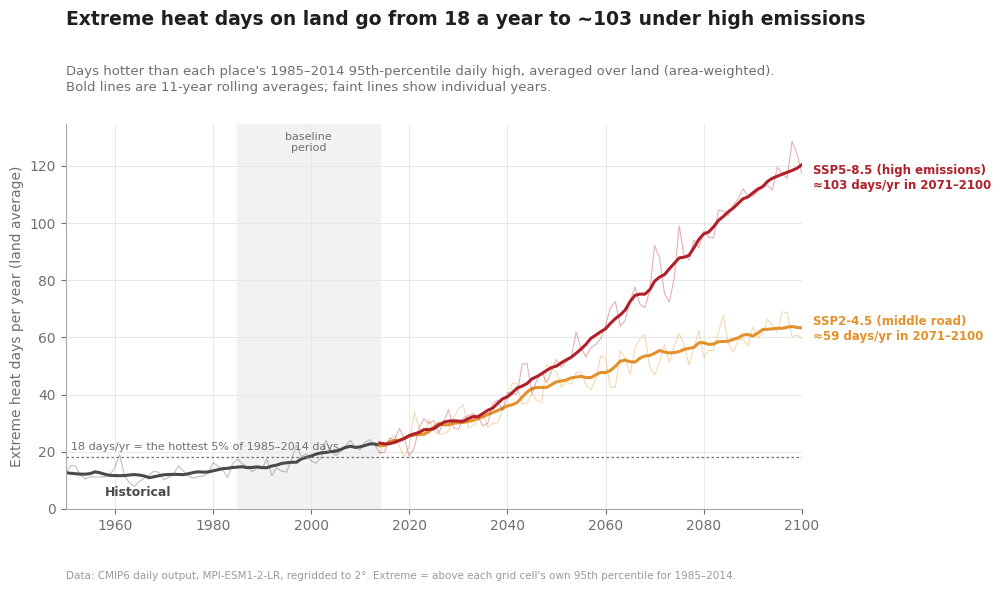

In [ ]:
lm = region_mean(heat, LAND, W)            # land average for each model, scenario and year
# single years jump around a lot (some summers are just hotter), so we also draw an 11-year
# rolling average centered on each year to show the trend
sm = lm.rolling(year=11, center=True, min_periods=6).mean()
base_val = float(pmean(lm.sel(scenario="ssp245"), BASE).median())
end = {sc: float(pmean(lm.sel(scenario=sc), FUTURE).median()) for sc in SCEN}
summary["land heat days/yr"] = {"1985-2014": round(base_val, 1), **{f"2071-2100 {k}": round(v, 1) for k, v in end.items()}}

fig, ax = plt.subplots(figsize=(9.5, 5))
ax.axvspan(*BASE, color="#f2f2f2", zorder=0)          # shade the baseline years
ax.text(np.mean(BASE), 0.98, "baseline\nperiod", transform=ax.get_xaxis_transform(), ha="center", va="top",
        fontsize=8, color=MUTED)
# history is drawn once in gray, then each scenario continues from 2014 in its own color
segs = [("historical", slice(1950, 2014), "ssp245")] + [(sc, slice(2014, 2100), sc) for sc in SCEN]
for key, yrs, sc in segs:
    raw, s = lm.sel(scenario=sc, year=yrs), sm.sel(scenario=sc, year=yrs)
    ax.plot(raw.year, raw.median("model"), color=COL[key], lw=0.8, alpha=0.35)     # faint: individual years
    if n > 1:   # with several models, shade between the lowest and highest model
        ax.fill_between(s.year, s.min("model"), s.max("model"), color=COL[key], alpha=0.15, lw=0)
    ax.plot(s.year, s.median("model"), color=COL[key], lw=2.2)                      # bold: the trend
ax.axhline(base_val, color=MUTED, lw=0.9, ls=(0, (2, 2)))
ax.text(1951, base_val + 2.5, f"{base_val:.0f} days/yr = the hottest 5% of 1985–2014 days", fontsize=8, color=MUTED)
ax.text(1958, float(sm.sel(scenario="ssp245", year=1962).median()) - 7, "Historical", fontsize=9,
        color=COL["historical"], weight="bold")
# label each line at its end instead of using a legend, so readers don't have to look back and forth
for sc in SCEN:
    y = float(sm.sel(scenario=sc).median("model").sel(year=2094))
    ax.annotate(f"{LAB[sc]}\n≈{end[sc]:.0f} days/yr in 2071–2100", xy=(2100, y), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=8.5, color=COL[sc], weight="bold",
                annotation_clip=False)
ax.set(xlim=(1950, 2100), ylim=(0, None), ylabel="Extreme heat days per year (land average)")
band = "shaded bands show the range across models" if n > 1 else "faint lines show individual years"
headline(fig, f"Extreme heat days on land go from {base_val:.0f} a year to ~{end['ssp585']:.0f} under high emissions",
         "Days hotter than each place's 1985–2014 95th-percentile daily high, averaged over land (area-weighted).\n"
         f"Bold lines are 11-year rolling averages; {band}.", FOOT)
save(fig, "fig1_heat_days_over_time.png")

## 2. Where extreme heat days increase most (SSP5-8.5)
Change in extreme heat days per year, 2071–2100 minus 1985–2014.
The surprise is that the tropics, not the poles, see the biggest jump: tropical land gains about 135 extra days a year versus 56 elsewhere. Places with very steady temperatures have a narrow range of “normal,” so even modest warming pushes them past their old 95th percentile on a huge number of days.

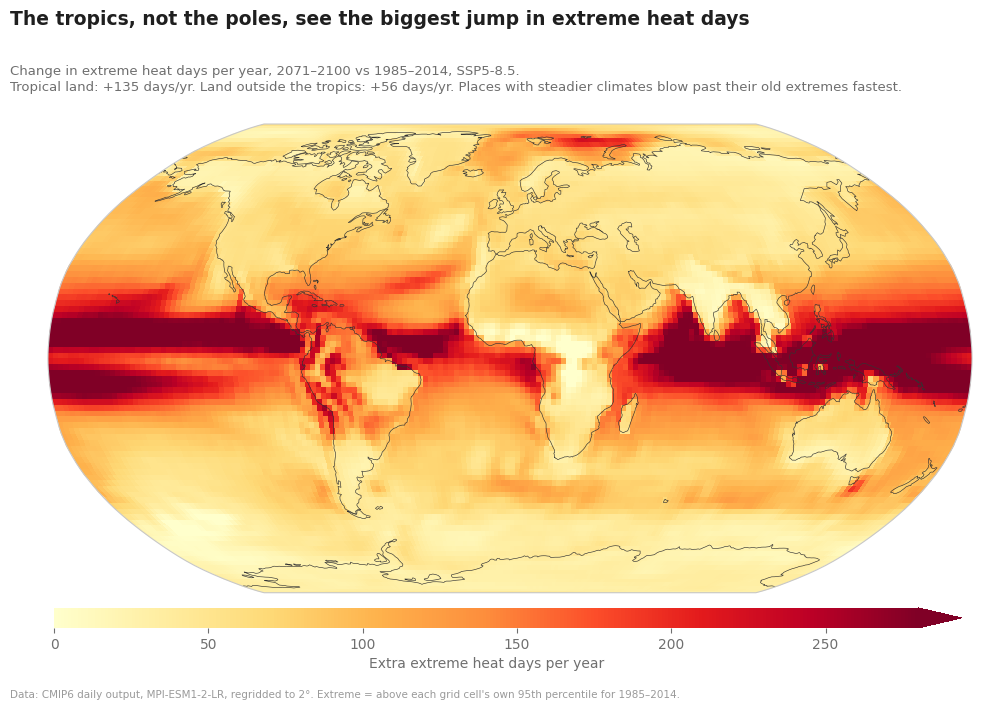

In [ ]:
# future average minus baseline average, per grid cell (median across models if we have several)
d_heat = (pmean(heat.sel(scenario="ssp585"), FUTURE) - pmean(heat.sel(scenario="ssp585"), BASE)).median("model")
# compare tropical land (between the Tropics of Cancer and Capricorn, ±23.5°) to the rest of the land
trop, extra = LAND & (np.abs(d_heat.lat) < 23.5), LAND & (np.abs(d_heat.lat) >= 23.5)
a, b = float(region_mean(d_heat, trop, W)), float(region_mean(d_heat, extra, W))
summary["extra heat days/yr, tropics vs elsewhere (SSP5-8.5)"] = (round(a), round(b))

# cap the color scale at the 98th percentile so a few extreme cells don't wash out the rest of the map
vmax = max(20, 20 * np.ceil(np.nanquantile(d_heat.where(LAND), 0.98) / 20))
fig, ax = world_map(d_heat, "YlOrRd", 0, vmax, "Extra extreme heat days per year", "max")
# the title depends on what the data actually shows
title = ("The tropics, not the poles, see the biggest jump in extreme heat days" if a > b
         else "Extreme heat days rise almost everywhere by the end of the century")
headline(fig, title,
         "Change in extreme heat days per year, 2071–2100 vs 1985–2014, SSP5-8.5.\n"
         f"Tropical land: +{a:.0f} days/yr. Land outside the tropics: +{b:.0f} days/yr. "
         "Places with steadier climates blow past their old extremes fastest.", FOOT)
save(fig, "fig2_heat_change_map.png")

## 3. Where heavy-rain days become more (or less) common (SSP5-8.5)
Percent change in heavy-rain days per year. We use *percent* change because a place with 2 heavy-rain days a year gaining 2 more is a much bigger deal than a place with 20 gaining 2.
Brown = fewer heavy-rain days, green = more. Heavy-rain days increase across 85% of land, but parts of the subtropics, like the Mediterranean coast, Central America, and Chile, get fewer.

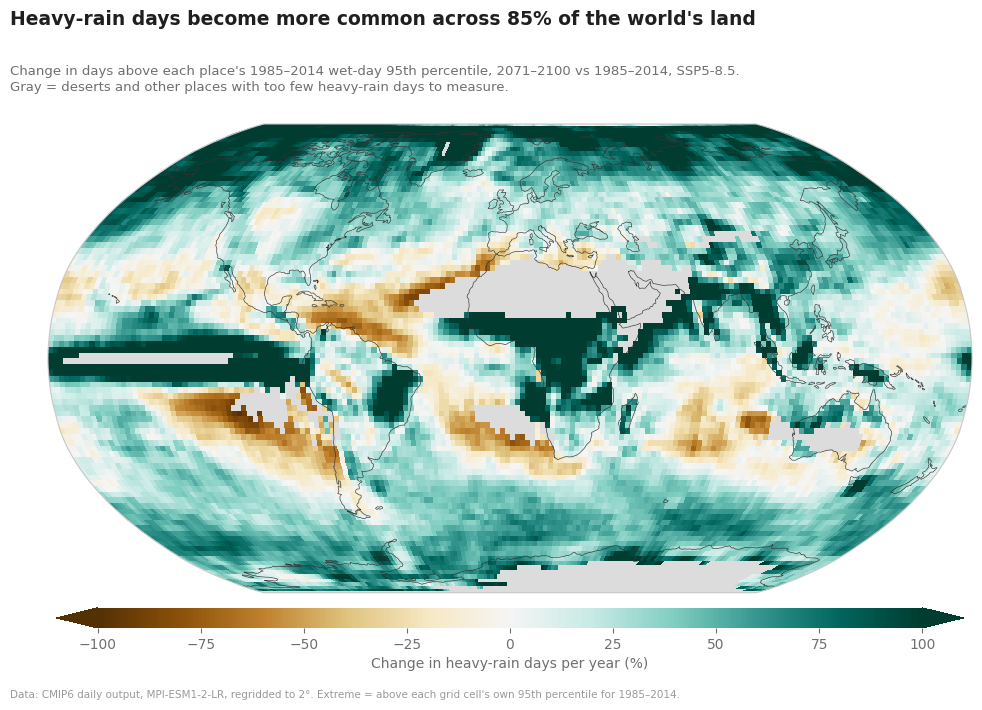

In [ ]:
# deserts might have less than 1 heavy-rain day a year, where percent change is meaningless
# (0.2 -> 0.4 days would be "+100%"), so we gray those out
ok = rain_base >= 1
pct = ((rain_fut - rain_base) / rain_base * 100).where(ok)
pct_med = pct.median("model").where(ok.all("model"))
vl = LAND & pct_med.notnull()
# share of land AREA (area-weighted, not just a count of grid cells) where heavy-rain days increase
share_up = float(W.where(vl & (pct_med > 0)).sum() / W.where(vl).sum())
summary["share of land with more heavy-rain days (SSP5-8.5)"] = round(share_up, 2)

# BrBG is a diverging colormap: white at 0%, so increases and decreases stand out equally
fig, ax = world_map(pct_med, "BrBG", -100, 100, "Change in heavy-rain days per year (%)", "both")
sub2 = "Gray = deserts and other places with too few heavy-rain days to measure."
if n >= 3:
    # with 3+ models, dot the places where fewer than 80% of models agree on whether rain goes up or down
    k = int(np.ceil(0.8 * n))
    agree = (np.sign(pct) == np.sign(pct_med)).sum("model") >= k
    yy, xx = np.meshgrid(LAT, LON, indexing="ij")
    dis = (~agree & pct_med.notnull()).values
    xx = ((xx + 180) % 360) - 180
    ax.scatter(xx[dis], yy[dis], s=1.6, color="#2b2b2b", alpha=0.55, lw=0, transform=ccrs.PlateCarree(),
               label=f"Fewer than {k} of {n} models agree on the direction")
    ax.legend(loc="lower left", fontsize=8, markerscale=4, handletextpad=0.3)
    sub2 = "Dots mark places where models disagree. " + sub2
headline(fig, f"Heavy-rain days become more common across {share_up:.0%} of the world's land",
         "Change in days above each place's 1985–2014 wet-day 95th percentile, 2071–2100 vs 1985–2014, SSP5-8.5.\n" + sub2,
         FOOT)
save(fig, "fig3_rain_change_map.png")

## 4. Extreme heat days by decade, region and scenario
Decade averages for five regions: two halves of California plus three global regions for comparison.
Putting both scenarios side by side shows how much of the future increase depends on emissions. By the 2090s, high emissions bring about 1.6 to 2 times as many extreme heat days as the middle-road scenario, from about 1.7× in California to almost 2× in the Amazon.

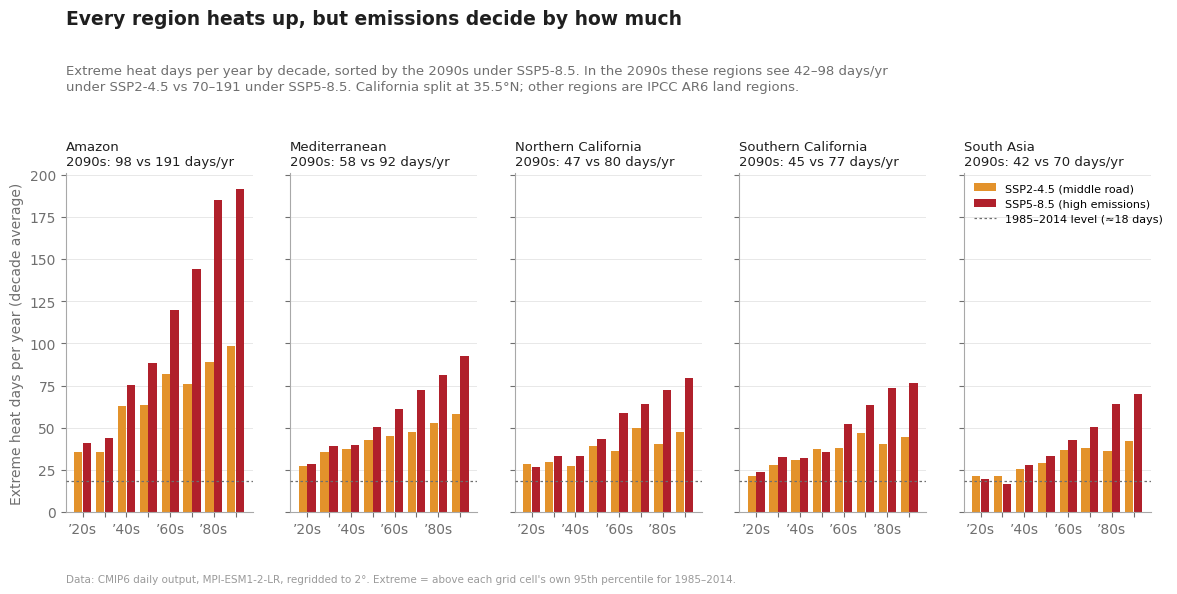

In [ ]:
decades = np.arange(2020, 2100, 10)
# regional average per year, then average each block of 10 years (coarsen) to get decade values
reg = {r: region_mean(heat, msk, W).sel(year=slice(2020, 2099)).coarsen(year=10).mean() for r, msk in REGIONS.items()}
top = lambda r, sc: float(reg[r].sel(scenario=sc).isel(year=-1).median())   # 2090s value
order = sorted(reg, key=lambda r: -top(r, "ssp585"))                       # biggest increase first

fig, axes = plt.subplots(1, len(order), figsize=(14, 4.4), sharey=True)   # sharey = same scale, easy to compare
x, rows = np.arange(len(decades)), []
for ax, r in zip(axes, order):
    rb = float(region_mean(pmean(heat.sel(scenario="ssp245"), BASE), REGIONS[r], W).median())
    for j, sc in enumerate(SCEN):
        g = reg[r].sel(scenario=sc)
        med = g.median("model").values
        xs = x + (j - 0.5) * 0.4                     # shift the two scenarios left/right so bars sit side by side
        ax.bar(xs, med, width=0.38, color=COL[sc], label=LAB[sc], zorder=2)
        if n > 1:   # thin lines show the lowest-to-highest model
            ax.vlines(xs, g.min("model"), g.max("model"), color="#2b2b2b", lw=0.7, alpha=0.6, zorder=3)
        rows += [dict(region=r, scenario=sc, decade=int(d), heat_days=round(float(v), 1)) for d, v in zip(decades, med)]
    ax.axhline(rb, color=MUTED, lw=0.9, ls=(0, (2, 2)), zorder=4)          # the ~18 days/yr baseline
    ax.set_xticks(x)
    ax.set_xticklabels([f"’{str(d)[2:]}s" if i % 2 == 0 else "" for i, d in enumerate(decades)])
    ax.grid(axis="x", visible=False)
    ax.set_title(f"{r}\n2090s: {top(r, 'ssp245'):.0f} vs {top(r, 'ssp585'):.0f} days/yr", loc="left",
                 fontsize=9.5, color=INK)
axes[0].set_ylabel("Extreme heat days per year (decade average)")
from matplotlib.lines import Line2D
hs, ls = axes[-1].get_legend_handles_labels()
hs.append(Line2D([], [], color=MUTED, lw=0.9, ls=(0, (2, 2)))); ls.append("1985–2014 level (≈18 days)")
axes[-1].legend(hs, ls, loc="upper left", fontsize=8)
lo = lambda sc: min(top(r, sc) for r in reg); hi = lambda sc: max(top(r, sc) for r in reg)
headline(fig, "Every region heats up, but emissions decide by how much",
         f"Extreme heat days per year by decade, sorted by the 2090s under SSP5-8.5. In the 2090s these regions see "
         f"{lo('ssp245'):.0f}–{hi('ssp245'):.0f} days/yr\nunder SSP2-4.5 vs {lo('ssp585'):.0f}–{hi('ssp585'):.0f} "
         "under SSP5-8.5. California split at 35.5°N; other regions are IPCC AR6 land regions.", FOOT, pad=0.5)
save(fig, "fig4_regions_by_decade.png")
pd.DataFrame(rows).to_csv(f"{OUT}/regions_by_decade.csv", index=False)

## 5. California summers: the hot tail shifts
This is the "why" behind all the other charts. If the whole distribution of summer highs slides a few degrees warmer,
the slice of days past the old "hottest 5%" line (the tail) grows much faster than the average does. Days past the old top-5% line (about 96°F) go from 5% of summer days to 21% under SSP2-4.5 and 47% under SSP5-8.5.

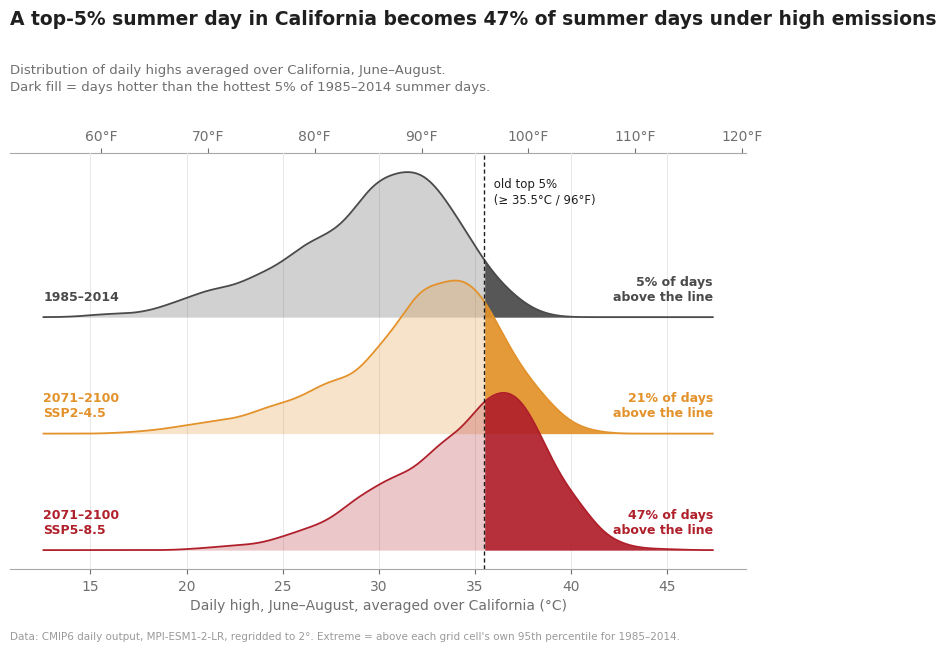

In [ ]:
# If we had several models, each one has its own bias (some run a bit warm or cool), so we shift each
# model to the same 1985-2014 average before pooling. With one model this changes nothing.
grand = float(np.mean([data[m]["ca_historical"].mean() for m in names]))
groups = {k: np.concatenate([data[m][f"ca_{k}"].values - float(data[m]["ca_historical"].mean()) for m in names]) + grand
          for k in ["historical"] + SCEN}
thr = float(np.quantile(groups["historical"], PCT))          # the old "hottest 5% of summer days" line
share = {k: float((v > thr).mean()) for k, v in groups.items()}   # fraction of days past that line
summary["CA summer days above old top-5%"] = {k: round(v, 2) for k, v in share.items()}

labels = {"historical": "1985–2014", "ssp245": "2071–2100\nSSP2-4.5", "ssp585": "2071–2100\nSSP5-8.5"}
allv = np.concatenate(list(groups.values()))
xs = np.linspace(allv.min() - 2, allv.max() + 2, 500)
# a KDE (kernel density estimate) is basically a smoothed histogram, so the curves are easy to compare
kde = {k: gaussian_kde(v)(xs) for k, v in groups.items()}
peak = max(v.max() for v in kde.values())
fig, ax = plt.subplots(figsize=(9.5, 5.4))
# ridgeline: stack the three curves vertically, slightly overlapping
for i, k in enumerate(groups):
    y0 = (len(groups) - 1 - i) * 1.0
    d = kde[k] / peak * 1.35
    ax.fill_between(xs, y0, y0 + d, color=COL[k], alpha=0.25, lw=0, zorder=2 + i)
    t = xs >= thr                                              # darker fill for the part past the old line
    ax.fill_between(xs[t], y0, y0 + d[t], color=COL[k], alpha=0.9, lw=0, zorder=2 + i)
    ax.plot(xs, y0 + d, color=COL[k], lw=1.3, zorder=2 + i)
    ax.text(xs[0], y0 + 0.12, labels[k], fontsize=9, color=COL[k], weight="bold", va="bottom")
    ax.text(xs[-1], y0 + 0.12, f"{share[k]:.0%} of days\nabove the line", ha="right", va="bottom",
            fontsize=9, color=COL[k], weight="bold")
ax.axvline(thr, color=INK, lw=1, ls=(0, (3, 2)), zorder=10)
ax.text(thr + 0.3, 2 + 1.2, f" old top 5%\n (≥ {thr:.1f}°C / {thr * 9 / 5 + 32:.0f}°F)", fontsize=8.5, color=INK, va="top")
ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.grid(axis="y", visible=False)
ax.set_xlabel("Daily high, June–August, averaged over California (°C)")
# second axis on top in °F, since most of our audience thinks in Fahrenheit
sec = ax.secondary_xaxis("top", functions=(lambda c: c * 9 / 5 + 32, lambda f: (f - 32) * 5 / 9))
sec.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:.0f}°F")); sec.tick_params(colors=MUTED)
headline(fig, f"A top-5% summer day in California becomes {share['ssp585']:.0%} of summer days under high emissions",
         "Distribution of daily highs averaged over California, June–August"
         + (f", pooled across {n} models (each shifted to the same 1985–2014 average)" if n > 1 else "")
         + ".\nDark fill = days hotter than the hottest 5% of 1985–2014 summer days.", FOOT, pad=0.3)
save(fig, "fig5_california_tail_shift.png")

## Key numbers for the writeup + data for our D3 site later

In [ ]:
for k, v in summary.items():
    print(f"{k}: {v}")
# save tidy CSVs now so the final D3 site can load them directly
lm.to_dataframe(name="heat_days").reset_index().to_csv(f"{OUT}/land_heat_days_by_year.csv", index=False)
xr.Dataset({"heat_change_days": d_heat, "rain_change_pct": pct_med}).to_dataframe().reset_index() \
  .to_csv(f"{OUT}/change_maps_ssp585.csv", index=False)
!zip -qr figures.zip figures && echo "figures.zip ready (Files panel on the left -> download)"

land heat days/yr: {'1985-2014': 18.3, '2071-2100 ssp245': 59.4, '2071-2100 ssp585': 103.0}
extra heat days/yr, tropics vs elsewhere (SSP5-8.5): (135, 56)
share of land with more heavy-rain days (SSP5-8.5): 0.85
CA summer days above old top-5%: {'historical': 0.05, 'ssp245': 0.21, 'ssp585': 0.47}
figures.zip ready (Files panel on the left -> download)


## 6. Export data for the D3 site
Run this after all the cells above. It saves `figures/extremes.json` and downloads it. Put that file in the site's `data` folder.

In [ ]:
# ===== EXPORT FOR THE D3 SITE =====
# Run this after all the chart cells above. It saves figures/extremes.json for the website.
import json

def flat(da, nd=0):
    """Grid -> flat list in the order the website expects (lat south->north, lon -180->180)."""
    da = da.assign_coords(lon=((da.lon + 180) % 360) - 180).sortby("lon").sortby("lat")
    vals = np.round(da.values.astype(float), nd)
    return [None if np.isnan(v) else (int(v) if nd == 0 else float(v)) for v in vals.ravel()]

web_lon = np.sort(((LON + 180) % 360) - 180)
lm_med = region_mean(heat, LAND, W).median("model")                     # land average, median model
years = [int(y) for y in lm_med.year.values]

heat_maps = {sc: flat((pmean(heat.sel(scenario=sc), FUTURE) - pmean(heat.sel(scenario=sc), BASE)).median("model"))
             for sc in SCEN}
ok = rain_base >= 1
rain_pct = ((rain_fut - rain_base) / rain_base * 100).where(ok).median("model").where(ok.all("model"))

region_rows = []
for r, msk in REGIONS.items():
    by_dec = region_mean(heat, msk, W).sel(year=slice(2020, 2099)).coarsen(year=10).mean().median("model")
    region_rows.append({
        "name": r,
        "base": round(float(region_mean(pmean(heat.sel(scenario="ssp245"), BASE), msk, W).median()), 1),
        **{sc: [round(float(v), 1) for v in by_dec.sel(scenario=sc).values] for sc in SCEN}})

# California summer highs as histograms, so the site can move the "old top 5%" line itself
edges = np.arange(np.floor(min(v.min() for v in groups.values())) - 1,
                  np.ceil(max(v.max() for v in groups.values())) + 1.25, 0.25)
ca_hist = {k: np.histogram(v, bins=edges)[0].tolist() for k, v in groups.items()}

site = {
    "models": names, "baseline": list(BASE), "future": list(FUTURE), "cell": 2.0,
    "lat": [float(v) for v in LAT], "lon": [float(v) for v in web_lon],
    "land": flat(LAND.astype(float)),
    "base_days": round(float(pmean(lm_med.sel(scenario="ssp245"), BASE)), 1),
    "series": {"years": years, **{sc: [round(float(v), 1) for v in lm_med.sel(scenario=sc).values] for sc in SCEN}},
    "maps": {"heat": heat_maps, "rain": {"ssp585": flat(rain_pct)}},
    "regions": {"decades": list(range(2020, 2100, 10)), "rows": region_rows},
    "ca": {"start": float(edges[0]), "width": 0.25, "thr": round(float(thr), 2), "counts": ca_hist},
}
with open(f"{OUT}/extremes.json", "w") as f:
    json.dump(site, f, separators=(",", ":"))
print(f"saved {OUT}/extremes.json ({os.path.getsize(f'{OUT}/extremes.json') / 1e6:.2f} MB)")
try:
    from google.colab import files
    files.download(f"{OUT}/extremes.json")
except ImportError:
    pass